In [2]:
#imports
import math
import os
import random
import re
import time
from collections import Counter
from dataclasses import dataclass,replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# --- Dataset (SST-2 from Hugging Face) ---
from datasets import load_dataset

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [18]:
@dataclass
class Config:
    # reproducibility
    seed: int = 42

    # data
    dataset_name: str = "nyu-mll/glue"
    dataset_config: str = "sst2"
    max_len: int = 64
    min_freq: int = 2
    val_fraction: float = 0.1
    batch_size: int = 64
    num_workers: int = 2
    num_classes: int = 2
    text_col: str = "sentence"
    label_col: str = "label"
    pad_token: str = "<pad>"
    unk_token: str = "<unk>"

    # shared by both models
    embed_dim: int = 128
    dropout: float = 0.3

    # transformer
    num_heads: int = 4
    d_ff: int = 512
    num_layers: int = 1

    # LSTM
    lstm_hidden: int = 128
    lstm_layers: int = 1
    lstm_bidirectional: bool = False

    # training (shared by both models)
    lr: float = 1e-3
    epochs: int = 10
    weight_decay: float = 0.0
    grad_clip: float = 1.0
    patience: int = 3
    label_smoothing: float = 0.1

    # checkpoints and outputs
    output_dir: str = "outputs"
    transformer_ckpt: str = "transformer_best.pt"
    lstm_ckpt: str = "lstm_best.pt"

    # visualization
    num_attn_examples: int = 4

    def __post_init__(self):
        assert self.embed_dim % self.num_heads == 0, "embed_dim must be divisible by num_heads"

cfg = Config()
set_seed(cfg.seed)
os.makedirs(cfg.output_dir, exist_ok=True)
print(cfg)

Config(seed=42, dataset_name='nyu-mll/glue', dataset_config='sst2', max_len=64, min_freq=2, val_fraction=0.1, batch_size=64, num_workers=2, num_classes=2, text_col='sentence', label_col='label', pad_token='<pad>', unk_token='<unk>', embed_dim=128, dropout=0.3, num_heads=4, d_ff=512, num_layers=1, lstm_hidden=128, lstm_layers=1, lstm_bidirectional=False, lr=0.001, epochs=10, weight_decay=0.0, grad_clip=1.0, patience=3, label_smoothing=0.1, output_dir='outputs', transformer_ckpt='transformer_best.pt', lstm_ckpt='lstm_best.pt', num_attn_examples=4)


In [4]:
#scaled dot product attention
def scaled_dot_product_attention(q, k, v, mask=None):
    d_k = q.size(-1)

    # Step 1 + 2: match scores, then scale
    scores = torch.matmul(q,k.transpose(-2,-1))/math.sqrt(d_k)

    # Mask: where mask is 0, block the position
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    # Step 3: softmax over the last dimension
    weights = F.softmax(scores,dim=-1)

    # Step 4: weighted sum of V
    output = torch.matmul(weights,v)

    return output, weights


In [ ]:
#testing the function
q = torch.randn(2, 5, 8)
k = torch.randn(2, 5, 8)
v = torch.randn(2, 5, 8)

out, w = scaled_dot_product_attention(q, k, v)
print("output shape:", out.shape)
print("weights shape:", w.shape)
print("row sums:", w.sum(dim=-1))

output shape: torch.Size([2, 5, 8])
weights shape: torch.Size([2, 5, 5])
row sums: tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]])


In [5]:
#multi head attention
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        # (batch, seq_len, d_model) -> (batch, num_heads, seq_len, d_k)
        batch_size, seq_len, _ = x.size()
        x = x.view(batch_size, seq_len, self.num_heads, self.d_k)
        return x.transpose(1, 2)

    def combine_heads(self, x):
        # (batch, num_heads, seq_len, d_k) -> (batch, seq_len, d_model)
        batch_size, _, seq_len, _ = x.size()
        x = x.transpose(1, 2).contiguous()
        return x.view(batch_size, seq_len, self.d_model)

    def forward(self, q, k, v, mask=None):
        q = self.split_heads(self.w_q(q))
        k = self.split_heads(self.w_k(k))
        v = self.split_heads(self.w_v(v))

        out, weights = scaled_dot_product_attention(q, k, v, mask)

        out = self.combine_heads(out)
        out = self.w_o(out)
        return out, weights

In [ ]:
mha = MultiHeadAttention(d_model=8, num_heads=2)
x = torch.randn(2, 5, 8)

out, w = mha(x, x, x)
print("output shape:", out.shape)
print("weights shape:", w.shape)
print("row sums are 1:", torch.allclose(w.sum(dim=-1), torch.ones(2, 2, 5)))

output shape: torch.Size([2, 5, 8])
weights shape: torch.Size([2, 2, 5, 5])
row sums are 1: True


In [6]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, num_heads)

        # feed-forward network: d_model -> d_ff -> ReLU -> d_model
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Sub-layer 1: self-attention (q, k, v are all x)
        attn_out, weights = self.attn(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_out))

        # Sub-layer 2: feed-forward
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))

        return x, weights

In [ ]:
block = EncoderBlock(d_model=8, num_heads=2, d_ff=32)
x = torch.randn(2, 5, 8)

out, w = block(x)
print("output shape:", out.shape)
print("weights shape:", w.shape)
print("same shape as input:", out.shape == x.shape)

output shape: torch.Size([2, 5, 8])
weights shape: torch.Size([2, 2, 5, 5])
same shape as input: True


In [7]:
#load SST-2
def load_sst2(cfg):
    dataset = load_dataset(cfg.dataset_name, cfg.dataset_config)

    # Carve our own validation set out of the training data.
    # stratify_by_column keeps the positive/negative ratio the same in both pieces.
    split = dataset["train"].train_test_split(
        test_size=cfg.val_fraction,
        seed=cfg.seed,
        stratify_by_column=cfg.label_col,
    )
    train_raw = split["train"]
    val_raw = split["test"]            # "test" is just the name the function gives our held-out piece
    test_raw = dataset["validation"]   # official validation set, used as our final test set
                                       # (the official test split has hidden labels)
    return train_raw, val_raw, test_raw

train_raw, val_raw, test_raw = load_sst2(cfg)
print("train:", len(train_raw), "| val:", len(val_raw), "| test:", len(test_raw))

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

train: 60614 | val: 6735 | test: 872


0 | as a pale successor 
1 | assured and stylish 
1 | a smile on your face and a grumble in your stomach 
1 | howard conjures the past via surrealist flourishes so overwrought you 'd swear he just stepped out of a buñuel retrospective . 
1 | reign 
train label share: {1: 0.558, 0: 0.442}
val label share: {1: 0.558, 0: 0.442}
test label share: {1: 0.509, 0: 0.491}

train sentence length (words):
count    60614.0
mean         9.4
std          8.1
min          1.0
25%          3.0
50%          7.0
75%         13.0
max         52.0
dtype: float64
95th percentile: 26.0 | 99th percentile: 35.0

test sentence length (words):
count    872.0
mean      19.5
std        8.8
min        2.0
25%       13.0
50%       19.0
75%       26.0
max       47.0
dtype: float64
95th percentile: 34.44999999999993 | 99th percentile: 42.0


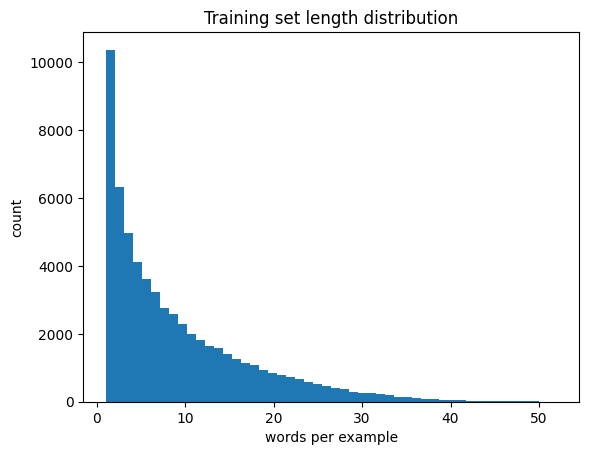

In [ ]:
# A few raw examples (label 1 = positive, 0 = negative)
for i in range(5):
    print(train_raw[i][cfg.label_col], "|", train_raw[i][cfg.text_col])

# Label balance in each split
for name, ds in [("train", train_raw), ("val", val_raw), ("test", test_raw)]:
    share = pd.Series(ds[cfg.label_col]).value_counts(normalize=True).round(3).to_dict()
    print(name, "label share:", share)

# Sentence lengths in words. Check train AND test, because train is mostly short
# phrases while the official validation/test set is made of full sentences.
for name, ds in [("train", train_raw), ("test", test_raw)]:
    lengths = pd.Series([len(t.split()) for t in ds[cfg.text_col]])
    print(f"\n{name} sentence length (words):")
    print(lengths.describe().round(1))
    print("95th percentile:", lengths.quantile(0.95), "| 99th percentile:", lengths.quantile(0.99))

# Length distribution of the training set
plt.hist([len(t.split()) for t in train_raw[cfg.text_col]], bins=50)
plt.xlabel("words per example")
plt.ylabel("count")
plt.title("Training set length distribution")
plt.show()

In [8]:
#tokenize and bulding vocabulary
def tokenize(text):
    # GLUE SST-2 text is already lowercase-ish and space-separated, so splitting on whitespace is enough
    return text.lower().strip().split()

def build_vocab(texts, min_freq, pad_token, unk_token):
    # Count how often each word appears
    counter = Counter()
    for t in texts:
        counter.update(tokenize(t))

    # Reserve ids 0 and 1 for the special tokens
    vocab = {pad_token: 0, unk_token: 1}

    # Add words from most to least frequent, skipping rare ones
    for word, count in counter.most_common():
        if count >= min_freq:
            vocab[word] = len(vocab)   # next free id
    return vocab

def encode(text, vocab, max_len, unk_token):
    unk_id = vocab[unk_token]
    # Words not in the vocabulary map to the unknown token
    ids = [vocab.get(tok, unk_id) for tok in tokenize(text)]
    return ids[:max_len]               # cut off anything beyond max_len

# Build the vocabulary from the TRAINING split only, to avoid data leakage
vocab = build_vocab(train_raw[cfg.text_col], cfg.min_freq, cfg.pad_token, cfg.unk_token)
pad_idx = vocab[cfg.pad_token]
vocab_size = len(vocab)
print("vocab size:", vocab_size, "| pad_idx:", pad_idx)

# Sanity check on one example
example = train_raw[0][cfg.text_col]
print(example)
print(encode(example, vocab, cfg.max_len, cfg.unk_token))

vocab size: 14118 | pad_idx: 0
as a pale successor 
[14, 4, 1476, 3834]


In [9]:
#pad, mask and DataLoaders
class SSTDataset(Dataset):
    def __init__(self, raw_ds, vocab, cfg):
        # Encode every sentence once, up front
        self.ids = [encode(t, vocab, cfg.max_len, cfg.unk_token) for t in raw_ds[cfg.text_col]]
        self.labels = list(raw_ds[cfg.label_col])

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.ids[i], self.labels[i]

def make_collate_fn(pad_idx):
    # The collate function turns a list of (ids, label) pairs into one padded batch
    def collate(batch):
        seqs, labels = zip(*batch)
        longest = max(len(s) for s in seqs)          # pad only to the longest sentence in this batch

        # Start with a tensor full of padding, then write the real ids over it
        input_ids = torch.full((len(seqs), longest), pad_idx, dtype=torch.long)
        for i, s in enumerate(seqs):
            input_ids[i, :len(s)] = torch.tensor(s)

        # True = real word, False = padding. Shape (batch, seq_len).
        # The model will reshape this to (batch, 1, 1, seq_len) for attention,
        # and reuse it for masked mean pooling.
        attention_mask = input_ids != pad_idx

        return input_ids, attention_mask, torch.tensor(labels, dtype=torch.long)
    return collate

def get_loaders(train_raw, val_raw, test_raw, vocab, cfg):
    collate = make_collate_fn(vocab[cfg.pad_token])

    def make(raw, shuffle):
        return DataLoader(
            SSTDataset(raw, vocab, cfg),
            batch_size=cfg.batch_size,
            shuffle=shuffle,
            collate_fn=collate,
            num_workers=cfg.num_workers,
        )

    # Shuffle only the training data
    return make(train_raw, True), make(val_raw, False), make(test_raw, False)

train_loader, val_loader, test_loader = get_loaders(train_raw, val_raw, test_raw, vocab, cfg)

# Sanity check on one batch
ids, mask, labels = next(iter(train_loader))
print("ids:", ids.shape, "| mask:", mask.shape, "| labels:", labels.shape)
print("real words in first sentence:", mask[0].sum().item())

ids: torch.Size([64, 29]) | mask: torch.Size([64, 29]) | labels: torch.Size([64])
real words in first sentence: 2


In [10]:
#The full model
class PositionalEncoding(nn.Module):
    # Fixed (not learned) sine/cosine pattern that tells the model where each word sits
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model)                           # one row per position
        position = torch.arange(0, max_len).unsqueeze(1).float()     # (max_len, 1): 0, 1, 2, ...
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)                 # even dimensions: sine
        pe[:, 1::2] = torch.cos(position * div_term)                 # odd dimensions: cosine

        # register_buffer = saved with the model and moved to GPU with it, but never trained
        self.register_buffer("pe", pe.unsqueeze(0))                  # (1, max_len, d_model)

    def forward(self, x):
        # x: (batch, seq_len, d_model). Add the pattern for the first seq_len positions.
        x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)


def masked_mean_pool(x, mask):
    # x: (batch, seq_len, dim) word vectors. mask: (batch, seq_len), True for real words.
    # Average only over real words, so padding never affects the sentence vector.
    # (Shared helper: the LSTM model will reuse it.)
    mask = mask.unsqueeze(-1).float()               # (batch, seq_len, 1)
    summed = (x * mask).sum(dim=1)                  # padding vectors are zeroed out before summing
    counts = mask.sum(dim=1).clamp(min=1)           # number of real words; clamp avoids dividing by 0
    return summed / counts


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, pad_idx, embed_dim, num_heads, d_ff,
                 num_layers, num_classes, max_len, dropout):
        super().__init__()
        # padding_idx keeps the <pad> embedding at zeros and never updates it
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.pos_enc = PositionalEncoding(embed_dim, max_len, dropout)
        # num_layers copies of encoder block from earlier
        self.layers = nn.ModuleList(
            [EncoderBlock(embed_dim, num_heads, d_ff, dropout) for _ in range(num_layers)]
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, input_ids, attention_mask, return_attn=False):
        # Reshape the (batch, seq_len) mask to (batch, 1, 1, seq_len) so it broadcasts
        # across heads and query positions inside attention (blocks padded KEYS)
        attn_mask = attention_mask.unsqueeze(1).unsqueeze(2)

        x = self.pos_enc(self.embedding(input_ids))      # (batch, seq_len, embed_dim)

        all_weights = []                                 # one attention tensor per layer
        for layer in self.layers:
            x, w = layer(x, attn_mask)
            all_weights.append(w)

        pooled = masked_mean_pool(x, attention_mask)     # (batch, embed_dim): one vector per sentence
        logits = self.classifier(self.dropout(pooled))   # (batch, num_classes)

        if return_attn:                                  # used later for the heatmaps
            return logits, all_weights
        return logits


# --- Throwaway sanity check ---
_test_model = TransformerClassifier(
    vocab_size=vocab_size, pad_idx=pad_idx, embed_dim=cfg.embed_dim, num_heads=cfg.num_heads,
    d_ff=cfg.d_ff, num_layers=cfg.num_layers, num_classes=cfg.num_classes,
    max_len=cfg.max_len, dropout=cfg.dropout,
)
_test_model.eval()
with torch.no_grad():
    logits, attn = _test_model(ids, mask, return_attn=True)
print("logits:", logits.shape)               # expect (64, 2)
print("attention (layer 0):", attn[0].shape) # expect (64, num_heads, seq_len, seq_len)

# Attention paid to padded positions should be exactly 0
pad_attention = (attn[0] * (~mask)[:, None, None, :].float()).sum().item()
print("attention on padding:", pad_attention)

logits: torch.Size([64, 2])
attention (layer 0): torch.Size([64, 4, 29, 29])
attention on padding: 0.0


In [11]:
#training and evaluation functions
def count_parameters(model):
    # Number of trainable weights, for the comparison table later
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def evaluate(model, loader, device):
    # Returns (average loss, accuracy) over a loader
    model.eval()                          # turns dropout off
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():                 # no gradients needed, saves memory and time
        for ids, mask, labels in loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            logits = model(ids, mask)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)             # weight by batch size
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, cfg, device, ckpt_path, writer=None):
    # One training function for BOTH models. Everything it needs comes in as arguments,
    # and the results come back as return values (no global variables).
    model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    epochs_without_improvement = 0
    start_time = time.time()

    for epoch in range(1, cfg.epochs + 1):
        model.train()                     # turns dropout on
        running_loss, correct, total = 0.0, 0, 0

        for ids, mask, labels in train_loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)

            optimizer.zero_grad()                         # clear old gradients
            logits = model(ids, mask)                     # forward pass
            loss = criterion(logits, labels)
            loss.backward()                               # compute gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)  # stop exploding gradients
            optimizer.step()                              # update weights

            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate(model, val_loader, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch:02d} | train loss {train_loss:.4f} acc {train_acc:.4f} "
              f"| val loss {val_loss:.4f} acc {val_acc:.4f}")

        # Keep the best model (by validation accuracy), not just the last epoch
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            epochs_without_improvement = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= cfg.patience:
                print(f"Early stopping: no improvement for {cfg.patience} epochs.")
                break

    history["total_time"] = time.time() - start_time
    history["best_val_acc"] = best_val_acc

    # Load the best weights back before returning, so evaluation uses the best epoch
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return model, history

In [12]:
#train the transformer
set_seed(cfg.seed)   # re-seed so this run gives the same result no matter what ran before

# Build a FRESH model from the config
transformer = TransformerClassifier(
    vocab_size=vocab_size, pad_idx=pad_idx, embed_dim=cfg.embed_dim, num_heads=cfg.num_heads,
    d_ff=cfg.d_ff, num_layers=cfg.num_layers, num_classes=cfg.num_classes,
    max_len=cfg.max_len, dropout=cfg.dropout,
)
print("Transformer parameters:", count_parameters(transformer))

transformer_ckpt_path = os.path.join(cfg.output_dir, cfg.transformer_ckpt)

transformer, transformer_history = train_model(
    transformer, train_loader, val_loader, cfg, device, transformer_ckpt_path
)

# Final evaluation on the official validation set (our test set), using the best checkpoint
test_loss, test_acc = evaluate(transformer, test_loader, device)
print(f"\nBest val acc: {transformer_history['best_val_acc']:.4f}")
print(f"Test acc: {test_acc:.4f} | training time: {transformer_history['total_time']:.1f}s")

Transformer parameters: 2005634
Epoch 01 | train loss 0.6230 acc 0.6658 | val loss 0.4472 acc 0.7860
Epoch 02 | train loss 0.5089 acc 0.7887 | val loss 0.3540 acc 0.8444
Epoch 03 | train loss 0.4439 acc 0.8408 | val loss 0.2990 acc 0.8756
Epoch 04 | train loss 0.4049 acc 0.8702 | val loss 0.2780 acc 0.8861
Epoch 05 | train loss 0.3798 acc 0.8884 | val loss 0.2592 acc 0.8968
Epoch 06 | train loss 0.3601 acc 0.9017 | val loss 0.2497 acc 0.9029
Epoch 07 | train loss 0.3465 acc 0.9113 | val loss 0.2407 acc 0.9076
Epoch 08 | train loss 0.3372 acc 0.9169 | val loss 0.2335 acc 0.9130
Epoch 09 | train loss 0.3292 acc 0.9223 | val loss 0.2217 acc 0.9183
Epoch 10 | train loss 0.3188 acc 0.9291 | val loss 0.2203 acc 0.9182

Best val acc: 0.9183
Test acc: 0.8085 | training time: 92.8s


In [13]:
#Building LSTM model
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, pad_idx, embed_dim, hidden_dim, num_layers,
                 bidirectional, num_classes, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,   # PyTorch only allows LSTM dropout with 2+ layers
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)  # bidirectional doubles the output size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(out_dim, num_classes)

    def forward(self, input_ids, attention_mask):
        x = self.dropout(self.embedding(input_ids))

        # "Packing" tells the LSTM where each sentence really ends, so it never
        # processes padding (this matters most for the backward direction)
        lengths = attention_mask.sum(dim=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(
            packed_out, batch_first=True, total_length=input_ids.size(1)
        )                                               # back to (batch, seq_len, out_dim)

        pooled = masked_mean_pool(out, attention_mask)  # same pooling helper as the transformer
        return self.classifier(self.dropout(pooled))

In [14]:
set_seed(cfg.seed)

lstm = LSTMClassifier(
    vocab_size=vocab_size, pad_idx=pad_idx, embed_dim=cfg.embed_dim,
    hidden_dim=cfg.lstm_hidden, num_layers=cfg.lstm_layers,
    bidirectional=cfg.lstm_bidirectional, num_classes=cfg.num_classes, dropout=cfg.dropout,
)
print("LSTM parameters:", count_parameters(lstm))

lstm_ckpt_path = os.path.join(cfg.output_dir, cfg.lstm_ckpt)

# Same training function, same loaders, same settings as the transformer
lstm, lstm_history = train_model(lstm, train_loader, val_loader, cfg, device, lstm_ckpt_path)

test_loss, lstm_test_acc = evaluate(lstm, test_loader, device)
print(f"\nBest val acc: {lstm_history['best_val_acc']:.4f}")
print(f"Test acc: {lstm_test_acc:.4f} | training time: {lstm_history['total_time']:.1f}s")

LSTM parameters: 1939458
Epoch 01 | train loss 0.5766 acc 0.7137 | val loss 0.3876 acc 0.8270
Epoch 02 | train loss 0.4490 acc 0.8345 | val loss 0.3047 acc 0.8726
Epoch 03 | train loss 0.3944 acc 0.8781 | val loss 0.2630 acc 0.8976
Epoch 04 | train loss 0.3621 acc 0.9016 | val loss 0.2368 acc 0.9072
Epoch 05 | train loss 0.3422 acc 0.9163 | val loss 0.2257 acc 0.9154
Epoch 06 | train loss 0.3253 acc 0.9273 | val loss 0.2168 acc 0.9210
Epoch 07 | train loss 0.3156 acc 0.9334 | val loss 0.2127 acc 0.9235
Epoch 08 | train loss 0.3053 acc 0.9392 | val loss 0.2056 acc 0.9286
Epoch 09 | train loss 0.2975 acc 0.9441 | val loss 0.2011 acc 0.9296
Epoch 10 | train loss 0.2901 acc 0.9491 | val loss 0.1996 acc 0.9320

Best val acc: 0.9320
Test acc: 0.8406 | training time: 131.0s


                        params  best_epoch  val_acc  min_val_loss  test_acc  \
model                                                                         
Transformer (1 block)  2005634           9   0.9183        0.2203    0.8085   
LSTM                   1939458          10   0.9320        0.1996    0.8406   

                       train_time_s  
model                                
Transformer (1 block)          92.8  
LSTM                          131.0  


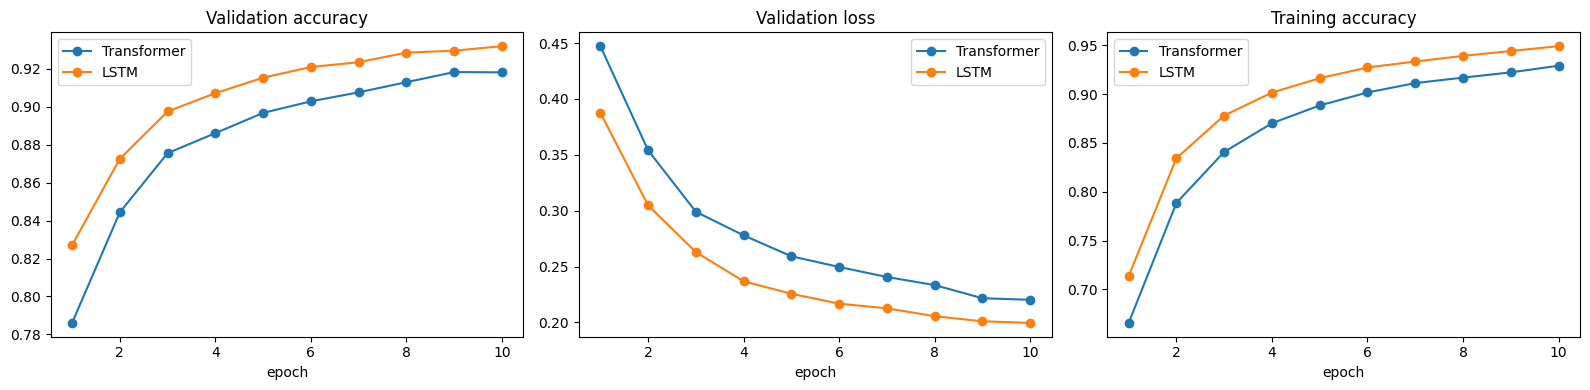

In [15]:
#comparison table and curves

# Re-evaluate both models on the test set so the numbers come from the saved best checkpoints
_, transformer_test_acc = evaluate(transformer, test_loader, device)
_, lstm_test_acc = evaluate(lstm, test_loader, device)

def summarize(name, model, history, test_acc):
    best_ep = int(np.argmax(history["val_acc"]))       # epoch with the best validation accuracy
    return {
        "model": name,
        "params": count_parameters(model),
        "best_epoch": best_ep + 1,
        "val_acc": round(history["val_acc"][best_ep], 4),
        "min_val_loss": round(min(history["val_loss"]), 4),
        "test_acc": round(test_acc, 4),
        "train_time_s": round(history["total_time"], 1),
    }

comparison = pd.DataFrame([
    summarize("Transformer (1 block)", transformer, transformer_history, transformer_test_acc),
    summarize("LSTM", lstm, lstm_history, lstm_test_acc),
]).set_index("model")
print(comparison)
comparison.to_csv(os.path.join(cfg.output_dir, "model_comparison.csv"))

# Learning curves: both models on the same axes
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, hist in [("Transformer", transformer_history), ("LSTM", lstm_history)]:
    epochs_x = range(1, len(hist["val_acc"]) + 1)
    axes[0].plot(epochs_x, hist["val_acc"], marker="o", label=name)
    axes[1].plot(epochs_x, hist["val_loss"], marker="o", label=name)
    axes[2].plot(epochs_x, hist["train_acc"], marker="o", label=name)

axes[0].set_title("Validation accuracy")
axes[1].set_title("Validation loss")
axes[2].set_title("Training accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(cfg.output_dir, "learning_curves.png"), dpi=150)
plt.show()

1. Overall metrics on the test set (positive = class 1)


,Accuracy,Precision,Recall,F1
Transformer,0.808,0.802,0.829,0.815
LSTM,0.841,0.846,0.840,0.843


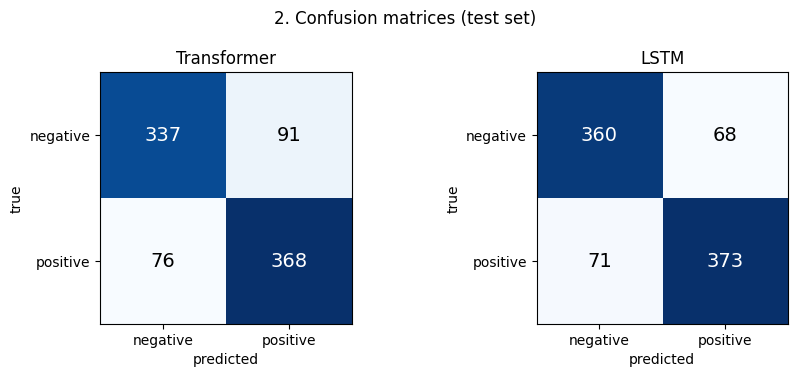

3. Accuracy by sentence length (words). Note: the 31+ bucket is small, so treat it with care.


,sentences,Transformer,LSTM,LSTM lead
1-10,152,0.875,0.908,+0.033
11-20,340,0.841,0.862,+0.021
21-30,275,0.782,0.811,+0.029
31+,105,0.676,0.752,+0.076


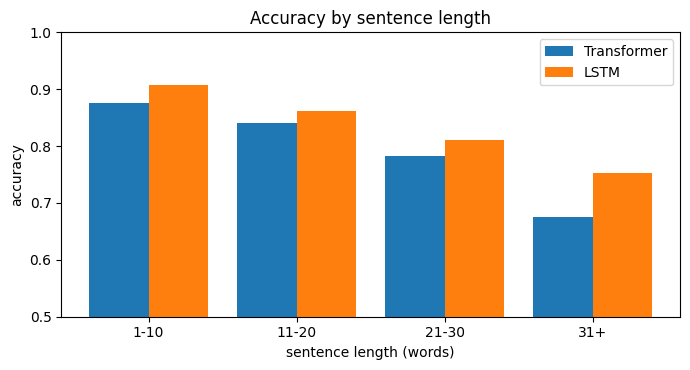

4. Agreement between the models (number of test sentences)


,LSTM right,LSTM wrong
Transformer right,653,52
Transformer wrong,80,87


McNemar exact p-value: 0.0184  (below 0.05 suggests the gap is not just luck on this test set)

5. Examples where the models disagree


,true,transformer,lstm,correct model,sentence
0,negative,positive,negative,LSTM,"it takes a strange kind of laziness to waste the talents of robert forster , anne meara , eugene levy , and reginald..."
1,positive,negative,positive,LSTM,"we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity ."
2,negative,negative,positive,Transformer,"... designed to provide a mix of smiles and tears , `` crossroads '' instead provokes a handful of unintentional how..."
3,negative,positive,negative,LSTM,"if the movie succeeds in instilling a wary sense of ` there but for the grace of god , ' it is far too self-consciou..."
4,positive,positive,negative,Transformer,"escaping the studio , piccoli is warmly affecting and so is this adroitly minimalist movie ."
5,positive,negative,positive,LSTM,"this is a story of two misfits who do n't stand a chance alone , but together they are magnificent ."
6,negative,negative,positive,Transformer,it 's one pussy-ass world when even killer-thrillers revolve around group therapy sessions .
7,positive,negative,positive,LSTM,fresnadillo 's dark and jolting images have a way of plying into your subconscious like the nightmare you had a week...
8,positive,negative,positive,LSTM,"we know the plot 's a little crazy , but it held my interest from start to finish ."
9,positive,negative,positive,LSTM,"hardly a masterpiece , but it introduces viewers to a good charitable enterprise and some interesting real people ."


In [16]:
from IPython.display import display
from scipy.stats import binomtest
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

LABELS = ["negative", "positive"]
HIGHLIGHT = "background-color: #2e7d32; color: white; font-weight: bold"   # dark green, white text (readable in dark mode)
pd.set_option("display.max_colwidth", 120)


def get_predictions(model, loader, device):
    # Predicted class for every sentence (test loader isn't shuffled, so order matches test_raw)
    model.eval()
    preds = []
    with torch.no_grad():
        for ids, mask, labels in loader:
            logits = model(ids.to(device), mask.to(device))
            preds.append(logits.argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


y_true = np.array(test_raw[cfg.label_col])
texts = test_raw[cfg.text_col]
preds = {
    "Transformer": get_predictions(transformer, test_loader, device),
    "LSTM": get_predictions(lstm, test_loader, device),
}

# ---------------------------------------------------------------
# 1. Overall metrics (best value in each column is highlighted)
# ---------------------------------------------------------------
metrics = pd.DataFrame({
    name: {
        "Accuracy": (p == y_true).mean(),
        "Precision": precision_score(y_true, p),
        "Recall": recall_score(y_true, p),
        "F1": f1_score(y_true, p),
    }
    for name, p in preds.items()
}).T
print("1. Overall metrics on the test set (positive = class 1)")
display(metrics.style.format("{:.3f}").highlight_max(axis=0, props=HIGHLIGHT))
metrics.round(4).to_csv(os.path.join(cfg.output_dir, "metrics.csv"))

# ---------------------------------------------------------------
# 2. Confusion matrices, side by side
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_true, p)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABELS)
    ax.set_yticks([0, 1]); ax.set_yticklabels(LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(2):
        for j in range(2):
            # white text on dark cells, black text on light cells
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.suptitle("2. Confusion matrices (test set)")
plt.tight_layout()
plt.savefig(os.path.join(cfg.output_dir, "confusion_matrices.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------
# 3. Accuracy by sentence length
# ---------------------------------------------------------------
lengths = np.array([len(t.split()) for t in texts])
bucket_labels = ["1-10", "11-20", "21-30", "31+"]
buckets = pd.cut(lengths, bins=[0, 10, 20, 30, 1000], labels=bucket_labels)

by_len = pd.DataFrame(index=bucket_labels)
by_len["sentences"] = pd.Series(buckets).value_counts().reindex(bucket_labels).values
for name, p in preds.items():
    by_len[name] = pd.Series(p == y_true).groupby(buckets, observed=False).mean().values
by_len["LSTM lead"] = by_len["LSTM"] - by_len["Transformer"]

print("3. Accuracy by sentence length (words). Note: the 31+ bucket is small, so treat it with care.")
display(by_len.style.format({"Transformer": "{:.3f}", "LSTM": "{:.3f}", "LSTM lead": "{:+.3f}"})
        .highlight_max(subset=["Transformer", "LSTM"], axis=1, props=HIGHLIGHT))
by_len.round(4).to_csv(os.path.join(cfg.output_dir, "accuracy_by_length.csv"))

x = np.arange(len(bucket_labels))
plt.figure(figsize=(7, 3.8))
plt.bar(x - 0.2, by_len["Transformer"], width=0.4, label="Transformer")
plt.bar(x + 0.2, by_len["LSTM"], width=0.4, label="LSTM")
plt.xticks(x, bucket_labels)
plt.xlabel("sentence length (words)"); plt.ylabel("accuracy")
plt.ylim(0.5, 1.0)
plt.title("Accuracy by sentence length")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(cfg.output_dir, "accuracy_by_length.png"), dpi=150)
plt.show()

# ---------------------------------------------------------------
# 4. Do the models disagree, and is the gap bigger than chance? (McNemar's exact test)
# ---------------------------------------------------------------
t_right = preds["Transformer"] == y_true
l_right = preds["LSTM"] == y_true
both_right = int((t_right & l_right).sum())
both_wrong = int((~t_right & ~l_right).sum())
only_t = int((t_right & ~l_right).sum())    # transformer right, LSTM wrong
only_l = int((~t_right & l_right).sum())    # LSTM right, transformer wrong

agreement = pd.DataFrame(
    [[both_right, only_t], [only_l, both_wrong]],
    index=["Transformer right", "Transformer wrong"],
    columns=["LSTM right", "LSTM wrong"],
)
print("4. Agreement between the models (number of test sentences)")
display(agreement)
p_value = binomtest(only_t, only_t + only_l, 0.5).pvalue
print(f"McNemar exact p-value: {p_value:.4f}  (below 0.05 suggests the gap is not just luck on this test set)\n")

# ---------------------------------------------------------------
# 5. Sentences where the models disagree
# ---------------------------------------------------------------
name_of = lambda c: LABELS[int(c)]
rows = []
for i in np.where(t_right != l_right)[0][:10]:
    rows.append({
        "true": name_of(y_true[i]),
        "transformer": name_of(preds["Transformer"][i]),
        "lstm": name_of(preds["LSTM"][i]),
        "correct model": "Transformer" if t_right[i] else "LSTM",
        "sentence": texts[int(i)][:120],     # cut long sentences for display
    })
print("5. Examples where the models disagree")
display(pd.DataFrame(rows))

[correct_positive] it 's a charming and often affecting journey . 


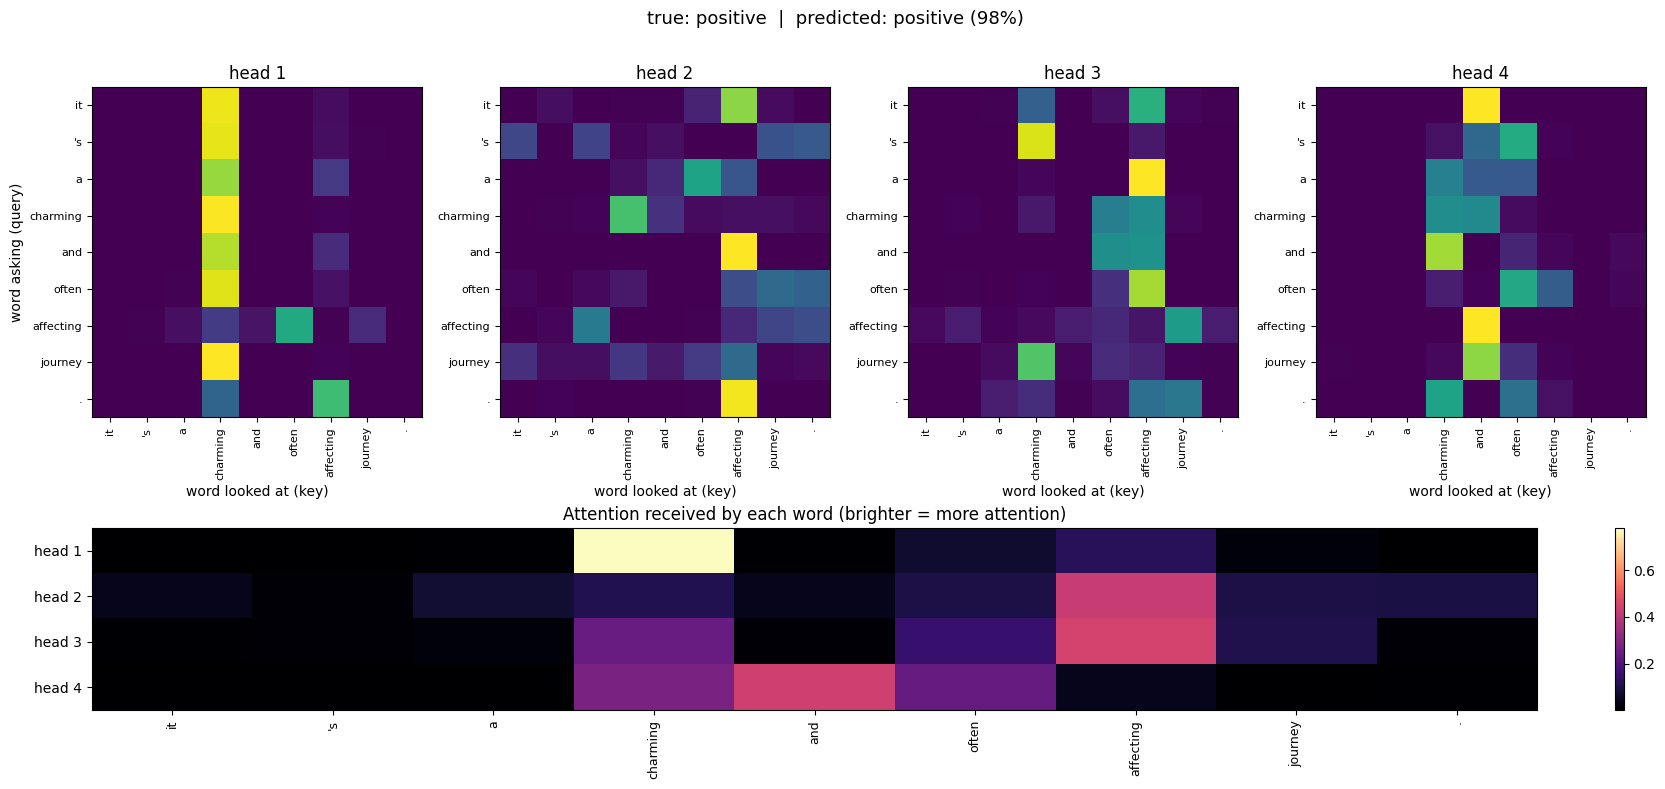

[correct_negative] it 's slow -- very , very slow . 


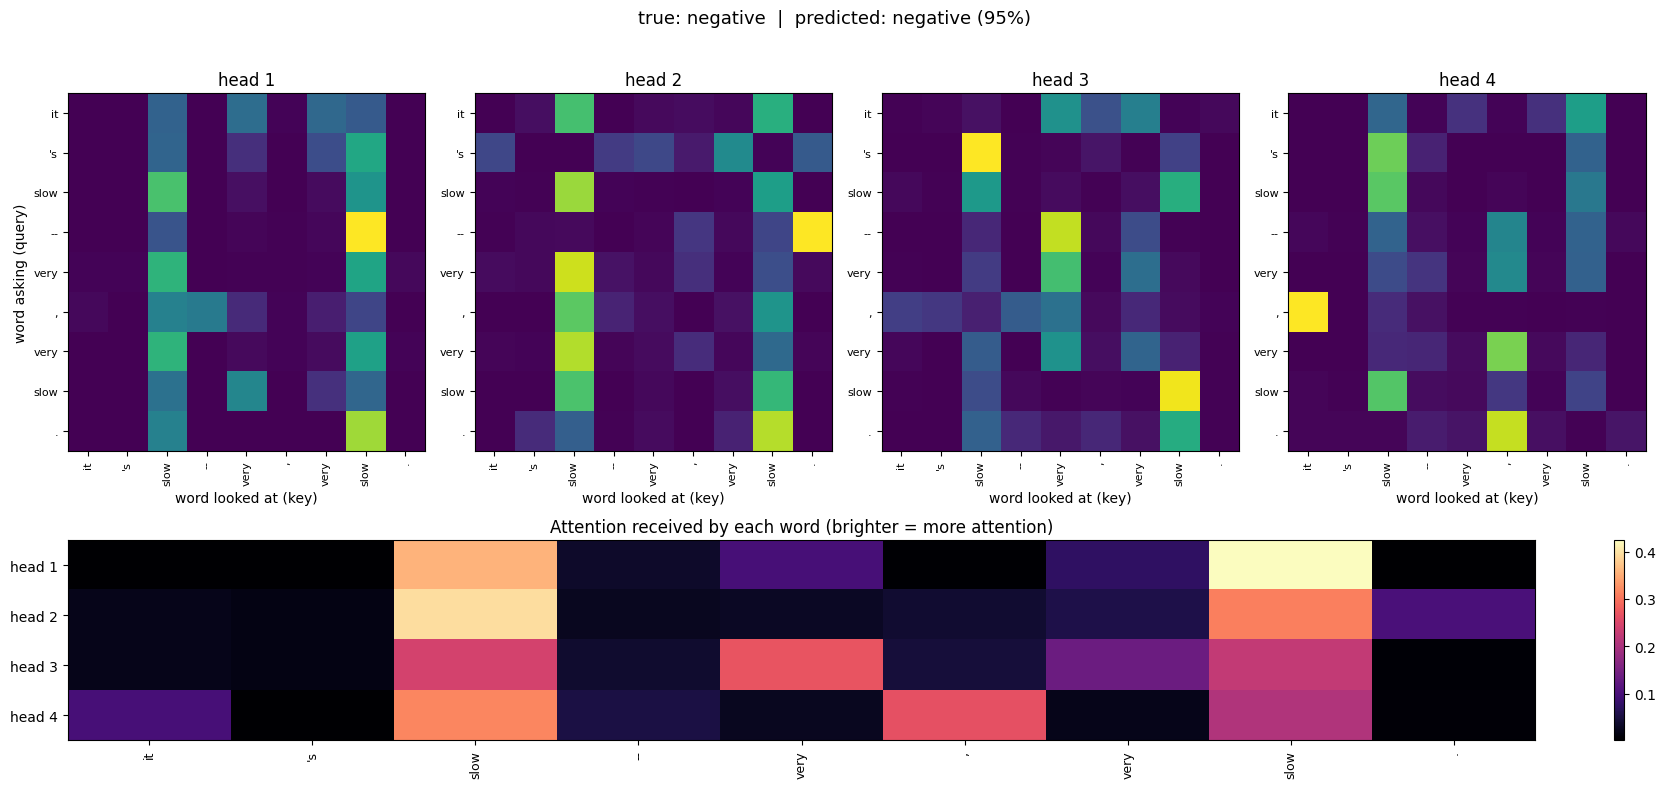

[wrong_1] manages to be both repulsively sadistic and mundane . 


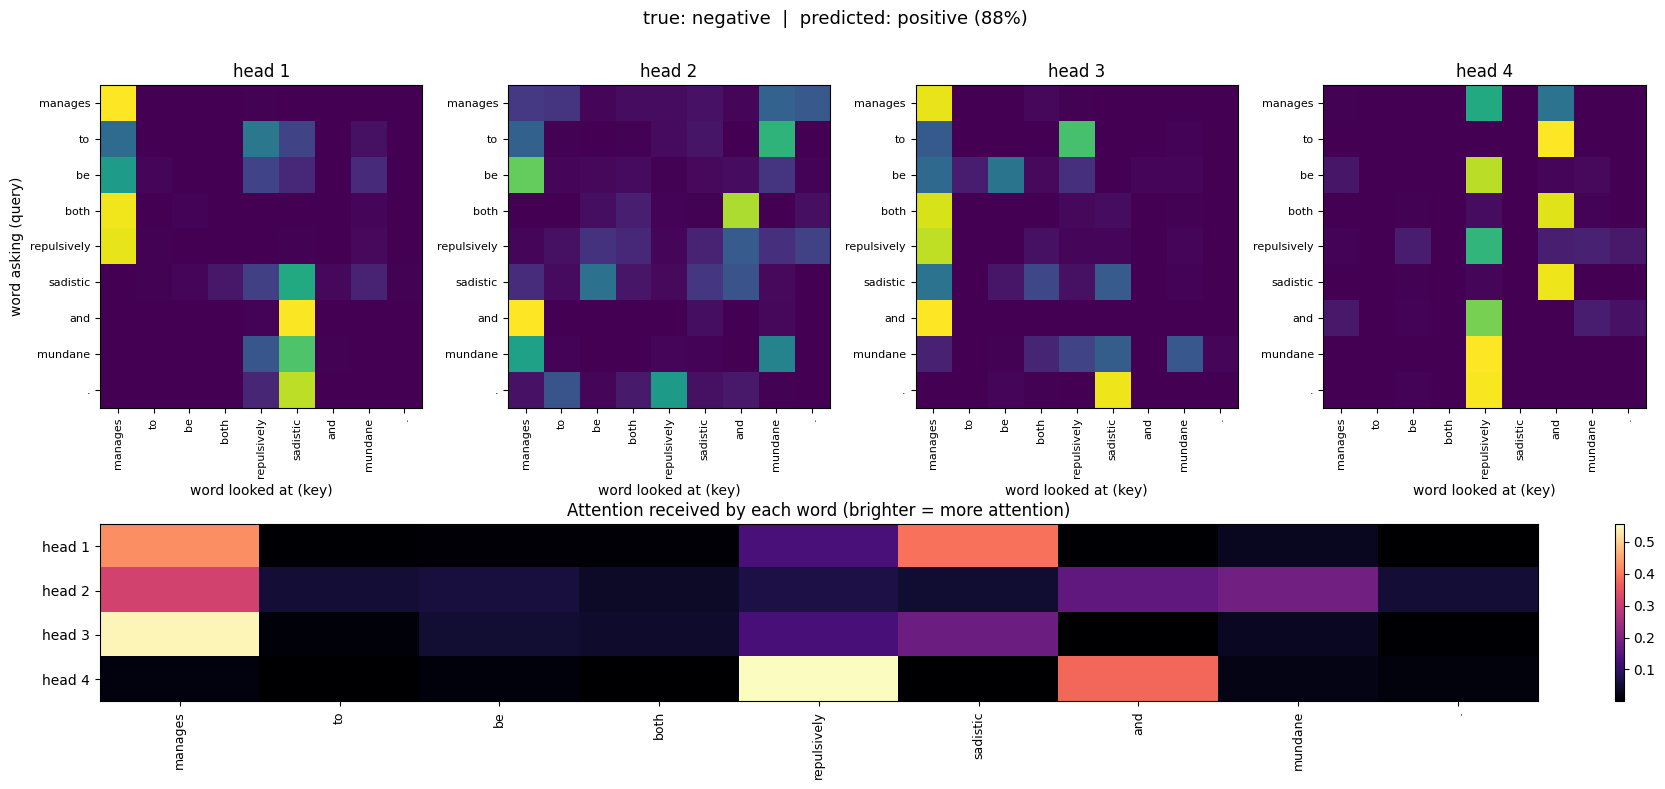

[wrong_2] the script kicks in , and mr. hartley 's distended pace and foot-dragging rhythms follow . 


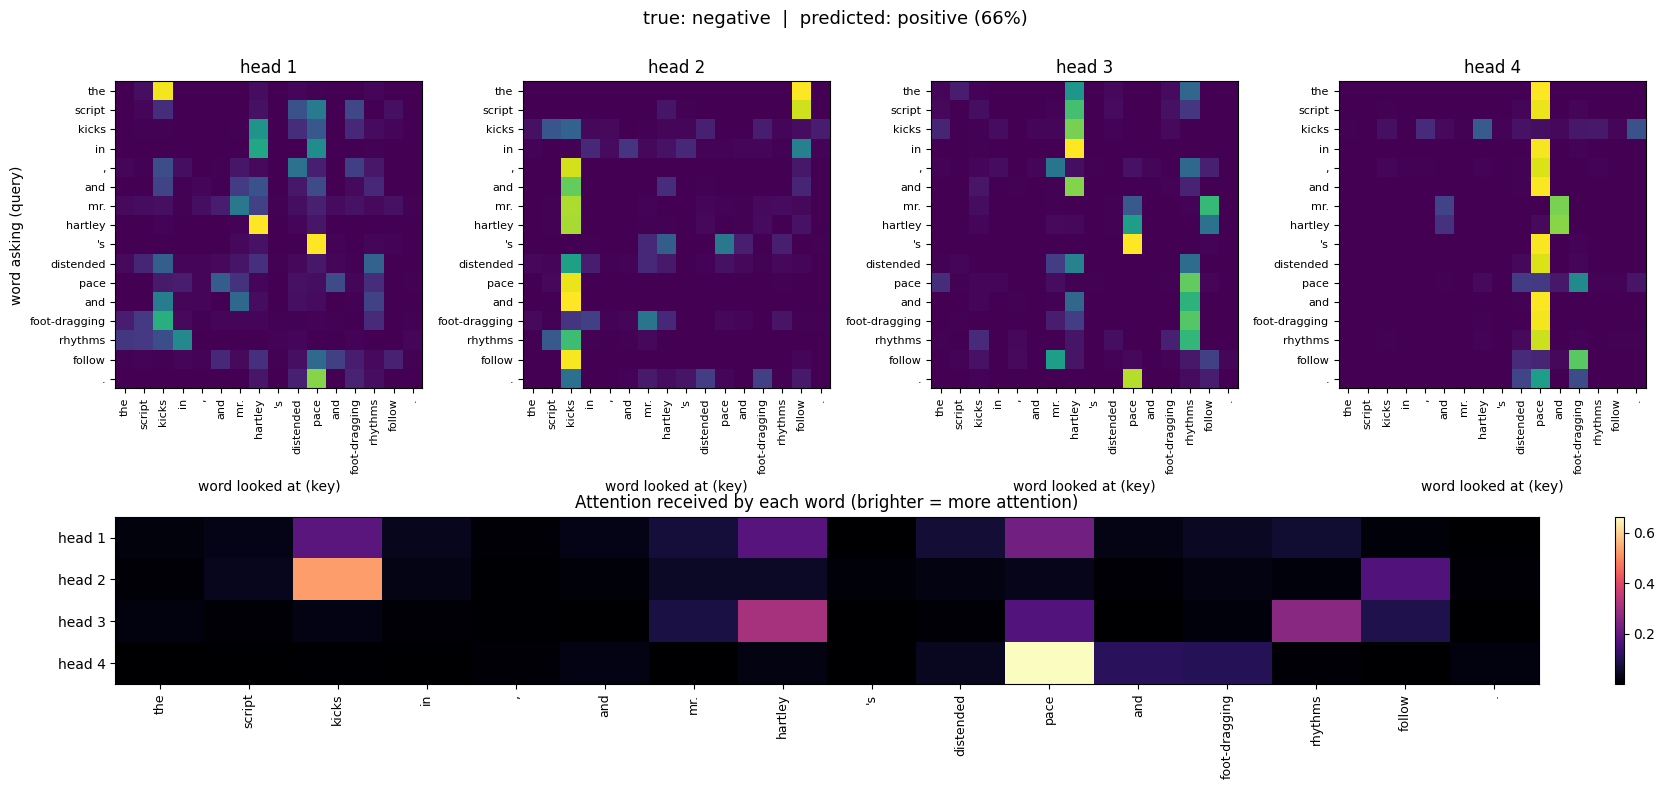

In [19]:
#visualising attention heads
LABEL_NAMES = ["negative", "positive"]


def plot_attention(model, text, true_label, vocab, cfg, device, save_name=None):
    # Draw the attention of one sentence: one heatmap per head, plus a strip of "attention received"
    model.eval()
    tokens = tokenize(text)[:cfg.max_len]                                      # words shown on the axes
    ids = torch.tensor([encode(text, vocab, cfg.max_len, cfg.unk_token)], device=device)
    mask = torch.ones_like(ids, dtype=torch.bool)                              # one sentence, so no padding

    with torch.no_grad():
        logits, all_weights = model(ids, mask, return_attn=True)
    probs = F.softmax(logits, dim=1)[0]
    pred = int(probs.argmax())

    w = all_weights[0][0].cpu().numpy()      # layer 0, sentence 0 -> (heads, seq, seq)
    n_heads = w.shape[0]

    fig = plt.figure(figsize=(4.2 * n_heads, 8))
    gs = fig.add_gridspec(2, n_heads, height_ratios=[3, 1.3])

    # Top row: one heatmap per head. Rows = word asking, columns = word being looked at.
    for h in range(n_heads):
        ax = fig.add_subplot(gs[0, h])
        ax.imshow(w[h], cmap="viridis")
        ax.set_xticks(range(len(tokens))); ax.set_xticklabels(tokens, rotation=90, fontsize=8)
        ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens, fontsize=8)
        ax.set_title(f"head {h + 1}")
        if h == 0:
            ax.set_ylabel("word asking (query)")
        ax.set_xlabel("word looked at (key)")

    # Bottom strip: how much attention each word receives from all other words, per head
    received = w.mean(axis=1)                # average over the asking words -> (heads, seq)
    ax2 = fig.add_subplot(gs[1, :])
    im = ax2.imshow(received, cmap="magma", aspect="auto")
    ax2.set_xticks(range(len(tokens))); ax2.set_xticklabels(tokens, rotation=90, fontsize=9)
    ax2.set_yticks(range(n_heads)); ax2.set_yticklabels([f"head {h + 1}" for h in range(n_heads)])
    ax2.set_title("Attention received by each word (brighter = more attention)")
    fig.colorbar(im, ax=ax2, fraction=0.02)

    fig.suptitle(f"true: {LABEL_NAMES[true_label]}  |  predicted: {LABEL_NAMES[pred]} ({probs[pred]:.0%})", fontsize=13)
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(cfg.output_dir, save_name), dpi=150, bbox_inches="tight")
    plt.show()


# --- Pick readable test sentences (8 to 18 words) ---
n_words = np.array([len(t.split()) for t in texts])
readable = (n_words >= 8) & (n_words <= 18)
t_pred = preds["Transformer"]

right_pos = np.where(readable & (y_true == 1) & (t_pred == 1))[0]
right_neg = np.where(readable & (y_true == 0) & (t_pred == 0))[0]
wrong = np.where(readable & (t_pred != y_true))[0]

chosen = []
if len(right_pos): chosen.append(("correct_positive", int(right_pos[0])))
if len(right_neg): chosen.append(("correct_negative", int(right_neg[0])))
if len(wrong) > 0: chosen.append(("wrong_1", int(wrong[0])))
if len(wrong) > 1: chosen.append(("wrong_2", int(wrong[1])))
chosen = chosen[:cfg.num_attn_examples]

for tag, i in chosen:
    print(f"[{tag}] {texts[i]}")
    plot_attention(transformer, texts[i], int(y_true[i]), vocab, cfg, device, save_name=f"attention_{tag}.png")

# **Final Summary**
A Transformer encoder was implemented from scratch in PyTorch for SST-2 sentiment classification and compared it with an LSTM classifier using the same data and training setup. The LSTM achieved 84.1% test accuracy, outperforming the Transformer at 80.8%, while the Transformer trained faster (92.8 seconds vs. 131 seconds). McNemar’s test (p = 0.018) indicated a statistically significant difference in their predictions. Both models performed worse on longer sentences, but the LSTM consistently achieved better accuracy across all sentence-length groups.

I addressed overfitting in the Transformer using dropout and label smoothing, selecting settings based on validation performance. Attention visualizations showed that the Transformer often focused on sentiment-bearing words, but this did not always lead to correct predictions. The LSTM’s stronger performance may relate to its sequential processing, while the Transformer’s single encoder block and mean pooling may limit its ability to capture complex sentiment relationships. These findings highlight that a more complex architecture does not necessarily perform better on a small dataset, particularly without pretrained representations.